# HO-Eval: Live Demo
**AIORI-3 Hackathon · PS-016 · Simulation-Based Handover Decision Evaluation for High-Mobility Users**
Team **A3-PS016-TC226**, Dayananda Sagar College of Engineering, Bengaluru

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/aiori-hackathon/A3-PS016-TC226/blob/main/demo.ipynb)

This notebook runs our handover simulator end to end. Click **Runtime → Run all** in Colab. It takes about one minute.

1. A UE moves along a high-speed railway past 12 gNBs.
2. Three handover policies run on **exactly the same** channel:
   * **A3 (fixed)**: the 3GPP A3 event with fixed hysteresis and TTT (baseline)
   * **Speed-adaptive A3**: TTT and hysteresis are reduced as speed increases
   * **CHO + adaptive**: Conditional Handover (Rel-16) with a speed-adaptive execution condition
3. We measure the 3GPP mobility KPIs: HO failures, radio link failures, ping-pong, interruption time and throughput.

In [1]:
# Setup: works in Google Colab and in a local clone of the repository
import os, sys
if "google.colab" in sys.modules and not os.path.exists("A3-PS016-TC226"):
    !git clone -q https://github.com/aiori-hackathon/A3-PS016-TC226.git
    %cd A3-PS016-TC226
    !pip -q install -r requirements.txt
sys.path.insert(0, "src")

from IPython.display import Image, display
from hoeval import load_config, build_channel, default_policies, run_experiment
from hoeval.executor import HOExecutor
from hoeval.analysis import plot_timeline, plot_kpis, summarise
print("HO-Eval ready")

HO-Eval ready


## 1. Scenario
Parameters come from `configs/hst.yaml`. Edit the YAML file to change the deployment, the A3 settings or the failure thresholds.

In [2]:
cfg = load_config("configs/hst.yaml")
print(f"Scenario      : {cfg.scenario}  ({cfg.n_cells} gNBs, ISD {cfg.isd_m:.0f} m, track {cfg.track_length_m/1000:.1f} km)")
print(f"Carrier       : {cfg.fc_ghz} GHz, {cfg.bandwidth_mhz:.0f} MHz, TR 38.901 UMa-LOS path loss, {cfg.shadow_std_db} dB shadowing")
print(f"A3 baseline   : Off {cfg.a3_offset_db} dB, Hys {cfg.hys_db} dB, TTT {cfg.ttt_ms} ms")
print(f"RLF model     : Qout {cfg.qout_db} dB, T310 {cfg.t310_ms} ms, HO prep delay {cfg.prep_delay_ms} ms")

Scenario      : hst  (12 gNBs, ISD 500 m, track 4.5 km)
Carrier       : 3.5 GHz, 100 MHz, TR 38.901 UMa-LOS path loss, 4 dB shadowing
A3 baseline   : Off 1.0 dB, Hys 2.0 dB, TTT 320 ms
RLF model     : Qout -8 dB, T310 1000 ms, HO prep delay 50 ms


## 2. One run at high speed
Change `SPEED` (km/h) and `SEED`, then re-run this cell. Green lines are successful handovers and orange dotted lines are HO failures (HOF). Red dotted lines would be radio link failures (RLF).

In [3]:
SPEED, SEED = 300, 3

ch = build_channel(cfg, SPEED, SEED)          # same channel for every policy
for policy in default_policies(cfg):
    kpi = HOExecutor(cfg).run(policy, ch)
    s = kpi.summary()
    print(f"{policy.name:<18}  HO={s['ho_count']:2d}  ping-pong={s['ping_pong_count']}  RLF={s['rlf_count']}  "
          f"HOF={s['hof_count']}  interruption={s['interruption_ms']} ms  throughput={s['mean_throughput_mbps']:.0f} Mbit/s")
    display(plot_timeline(kpi, ch, cfg))

A3 (fixed)          HO= 6  ping-pong=0  RLF=0  HOF=3  interruption=2520 ms  throughput=268 Mbit/s


<Figure size 1400x700 with 2 Axes>

Speed-adaptive A3   HO=11  ping-pong=2  RLF=0  HOF=0  interruption=480 ms  throughput=289 Mbit/s

<Figure size 1400x700 with 2 Axes>

CHO + adaptive      HO=11  ping-pong=2  RLF=0  HOF=0  interruption=440 ms  throughput=290 Mbit/s


<Figure size 1400x700 with 2 Axes>

## 3. Quick speed sweep
This runs 5 seeds per speed, so it takes a few seconds. The full results in Section 4 use 20 seeds per speed (`python scripts/run_experiment.py --runs 20`).

 km/h  policy             fail/run ping-pong interr. ms  Mbit/s
   30  A3 (fixed)             0.00     0.000        408   294.2
   30  CHO + adaptive         0.00     0.000        408   294.3
   30  Speed-adaptive A3      0.00     0.000        408   294.2
  120  A3 (fixed)             0.60     0.000        684   283.8
  120  CHO + adaptive         0.00     0.067        488   288.8
  120  Speed-adaptive A3      0.00     0.067        488   288.4
  200  A3 (fixed)             1.20     0.000       1236   281.1
  200  CHO + adaptive         0.00     0.185        472   293.9
  200  Speed-adaptive A3      0.00     0.204        488   293.3
  300  A3 (fixed)             2.20     0.000       2624   267.4
  300  CHO + adaptive         0.00     0.127        424   293.9
  300  Speed-adaptive A3      0.00     0.152        448   292.8
  400  A3 (fixed)             3.40     0.000       4040   244.9
  400  CHO + adaptive         0.00     0.144        454   293.5
  400  Speed-adaptive A3      0.20     0

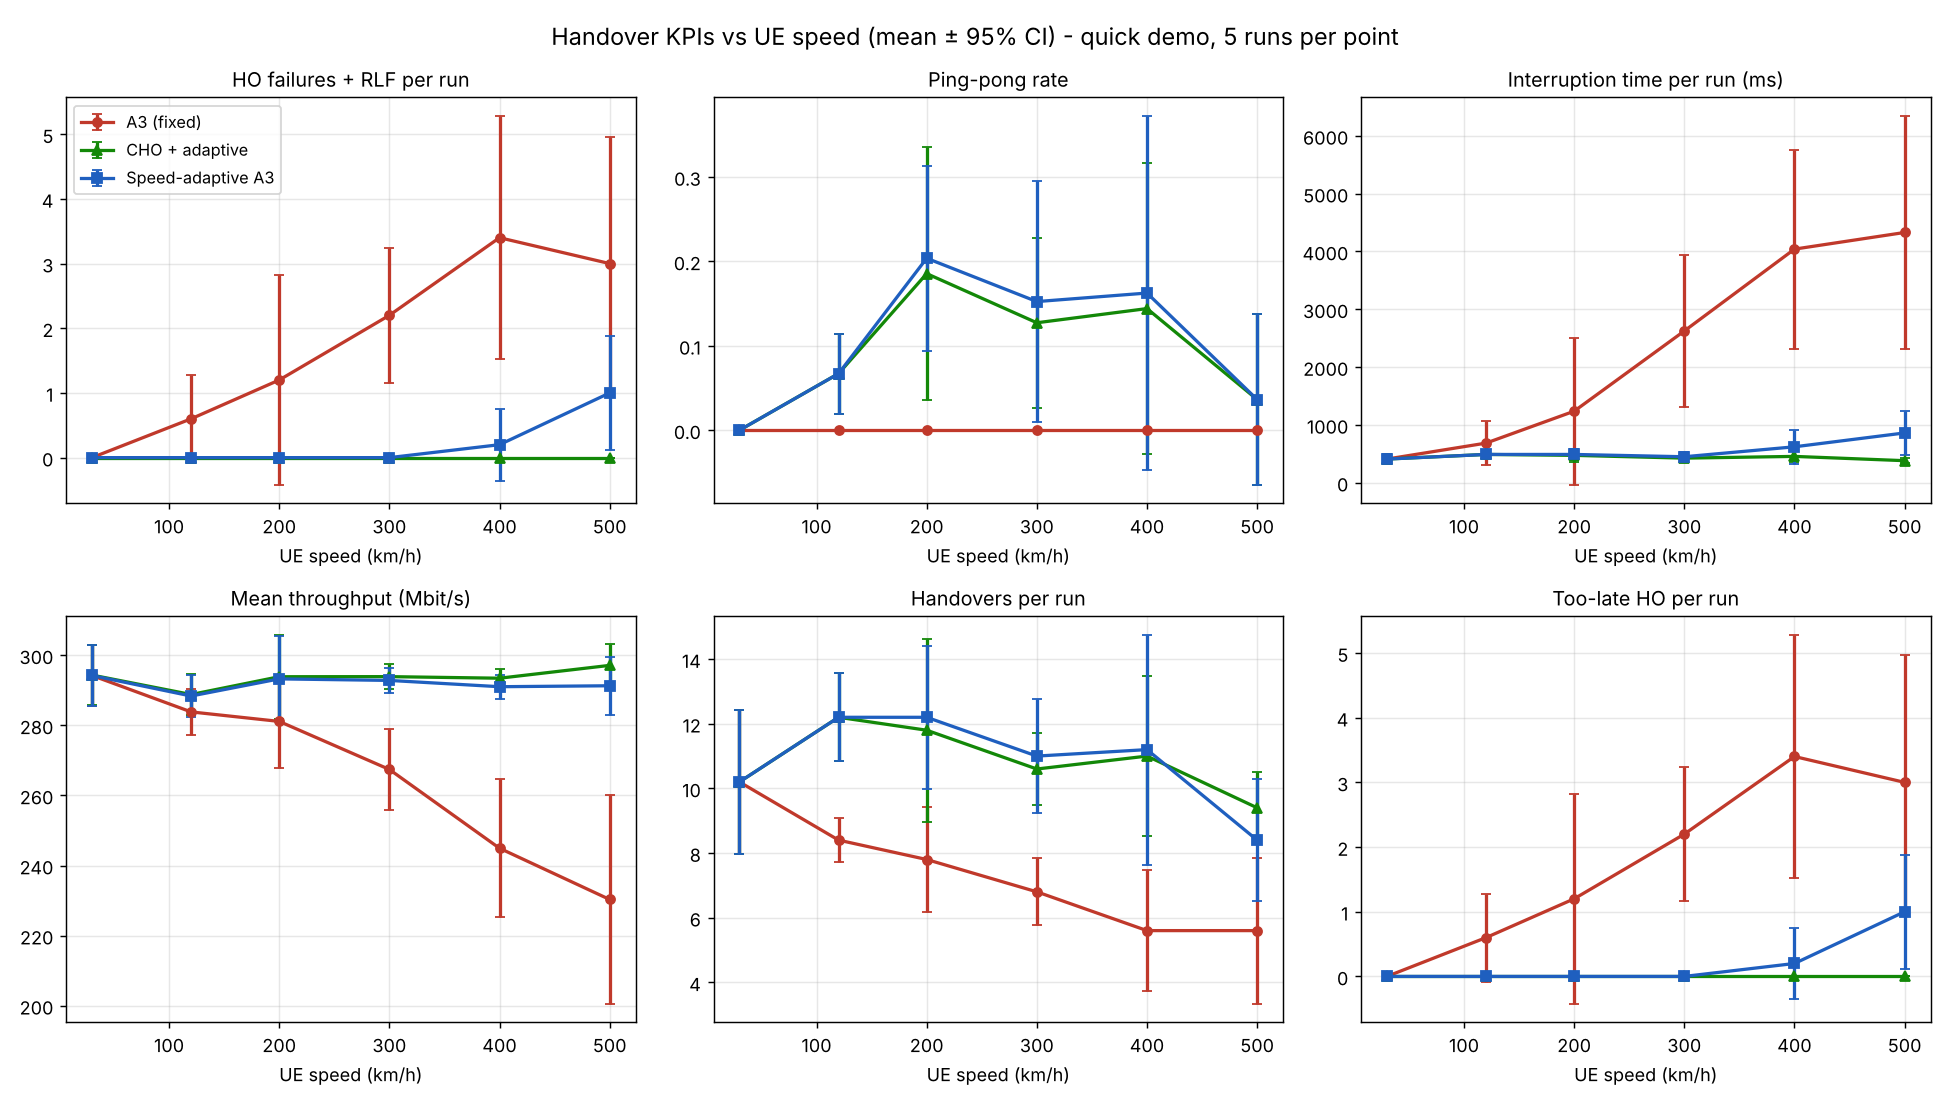

In [4]:
speeds = [30, 120, 200, 300, 400, 500]
rows = run_experiment(cfg, speeds, n_runs=5, workers=os.cpu_count() or 1)
summary = summarise(rows)

print(f"{'km/h':>5}  {'policy':<18} {'fail/run':>8} {'ping-pong':>9} {'interr. ms':>10} {'Mbit/s':>7}")
for r in summary:
    print(f"{r['speed_kmh']:>5.0f}  {r['policy']:<18} {r['failures_mean']:>8.2f} {r['ping_pong_rate_mean']:>9.3f} "
          f"{r['interruption_ms_mean']:>10.0f} {r['mean_throughput_mbps_mean']:>7.1f}")

plot_kpis(summary, "results/demo", title_suffix=" - quick demo, 5 runs per point")
display(Image("results/demo/kpi_vs_speed.png"))

## 4. Full experiment results (20 runs per speed)
These are pre-computed and stored in `results/hst/`.

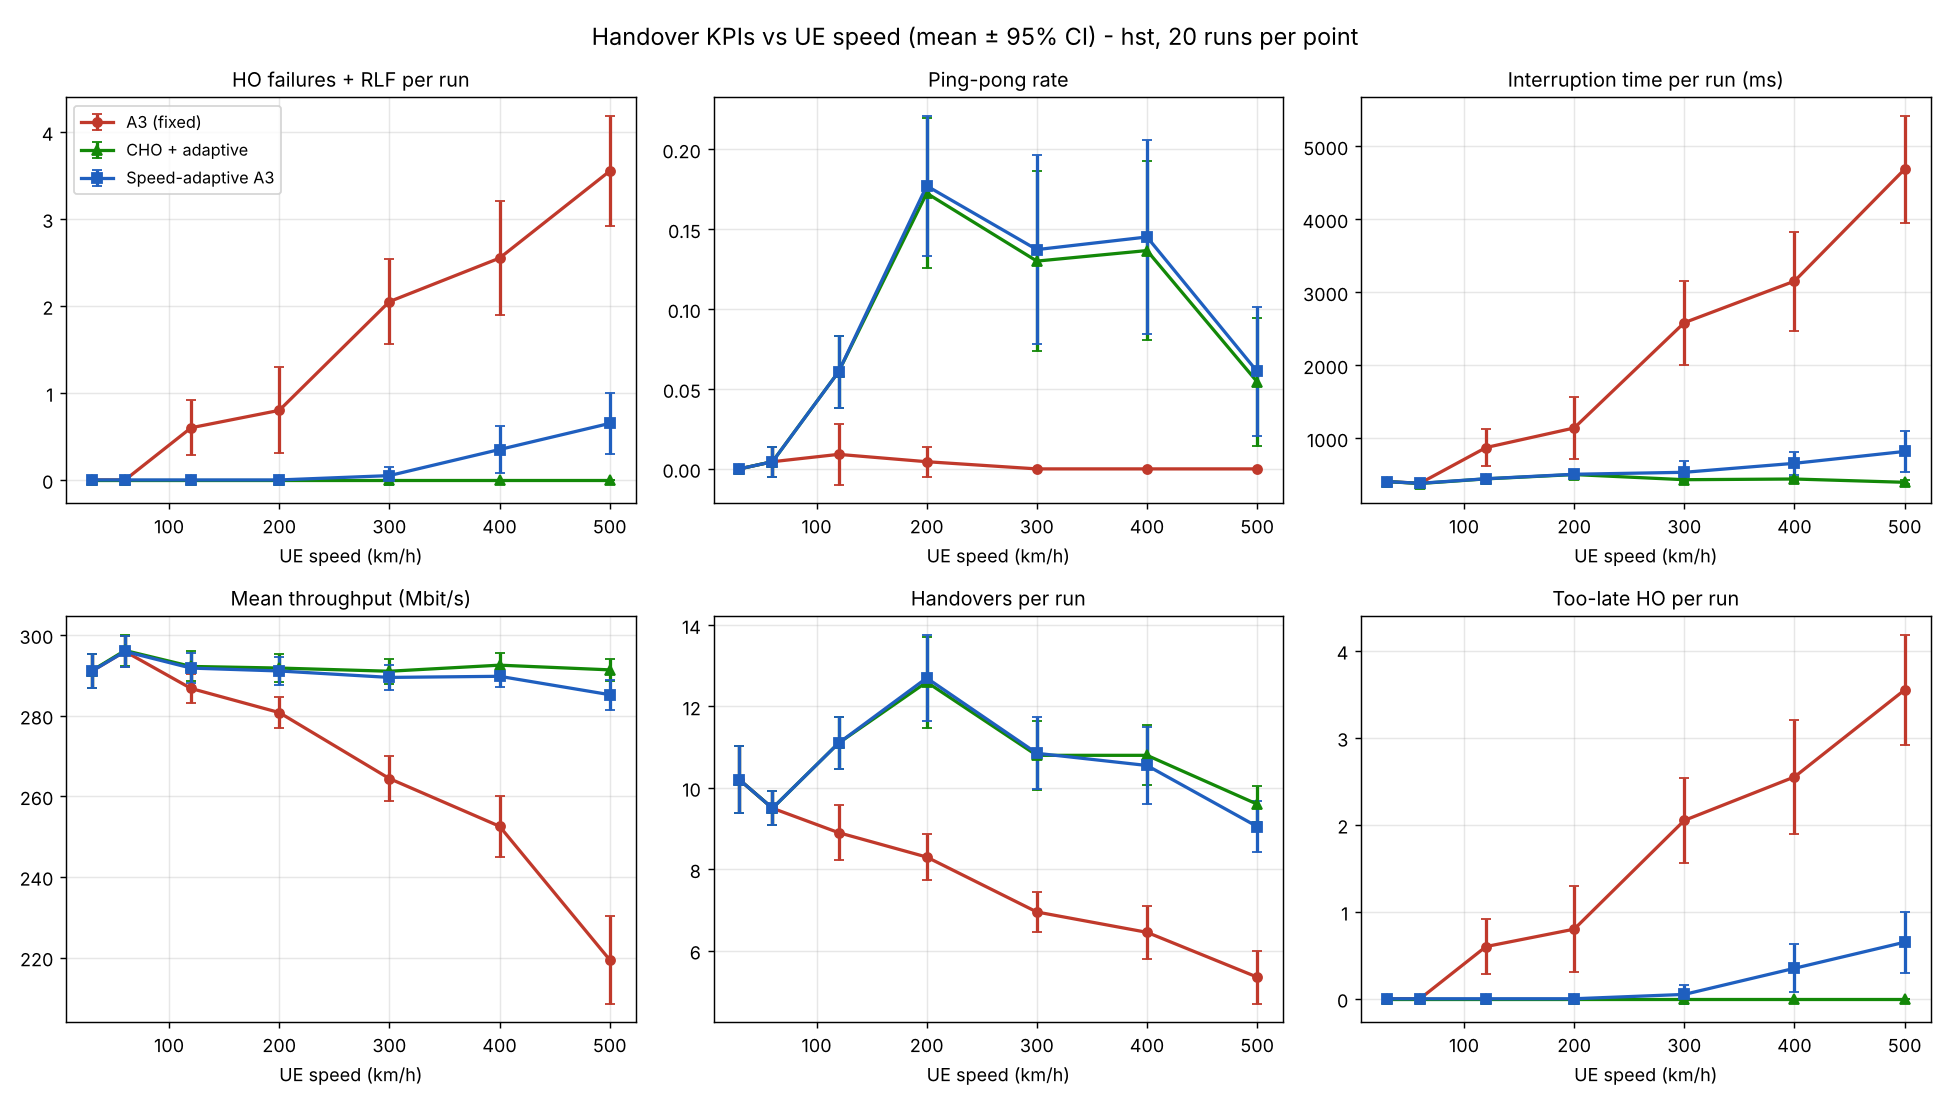

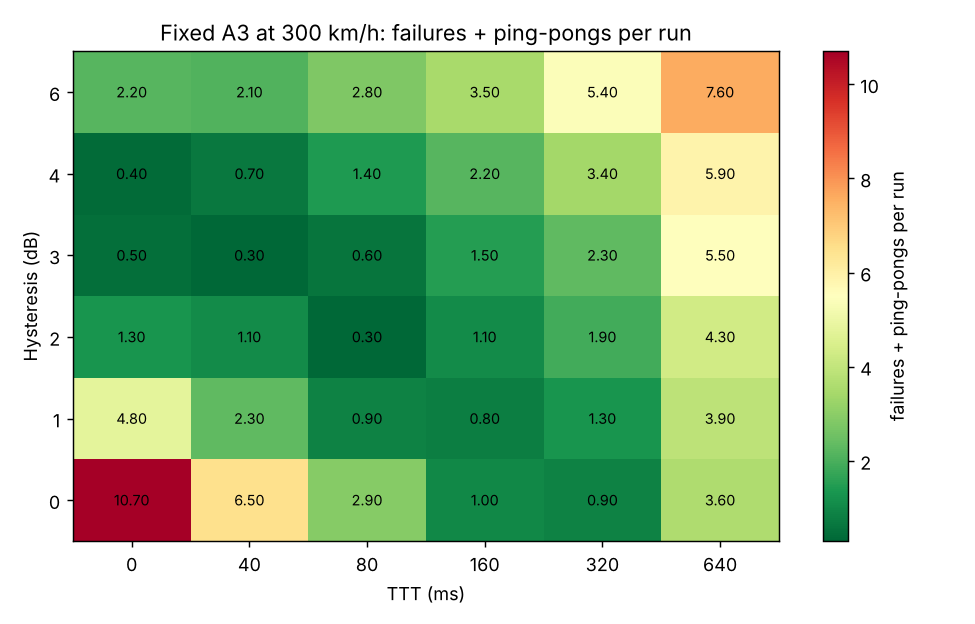

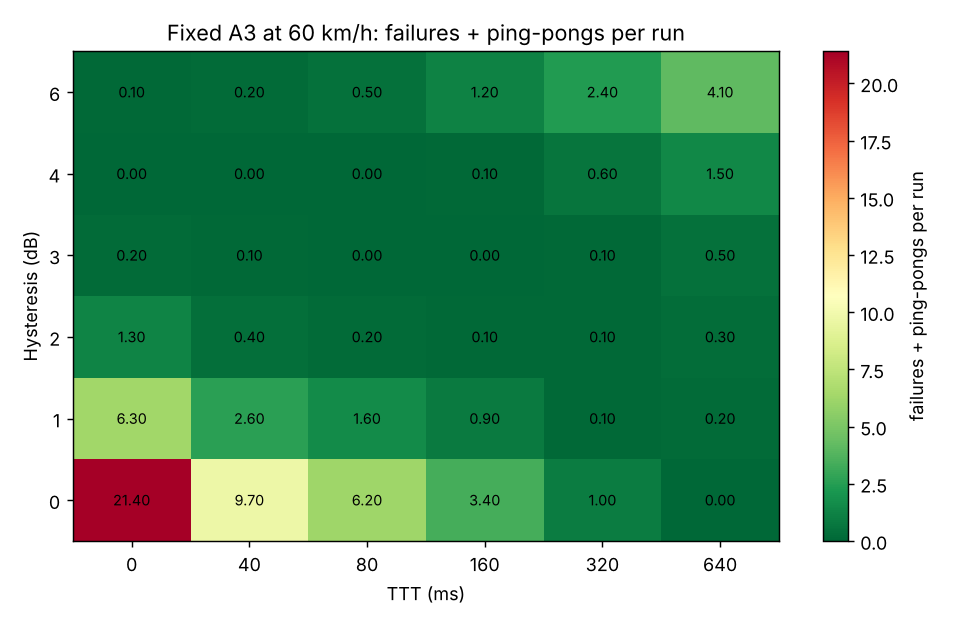

In [5]:
display(Image("results/hst/kpi_vs_speed.png"))
display(Image("results/hst/a3_sweep_300kmh.png"))
display(Image("results/hst/a3_sweep_60kmh.png"))

## 5. Observations
* **Fixed A3 breaks down as speed grows.** At 500 km/h it has about 3.5 failures per 4.5 km run, almost all of them *too-late* handovers, and throughput drops by about 25%.
* **Speed-adaptive A3** removes most failures by triggering earlier. The cost is more ping-pong in the 120–400 km/h range, because the hysteresis also shrinks.
* **CHO + adaptive** had **zero failures at every speed** in our runs, because the HO command is received early while the serving link is still good. It has the lowest interruption time and the highest throughput at high speed.
* The Hys/TTT sweeps show that the best fixed setting at 60 km/h (Hys 0 dB, TTT 640 ms) is very different from the best at 300 km/h (Hys 2 dB, TTT 80 ms). **No single fixed setting suits every speed**, which is the motivation for speed-aware handover.

**Next steps:** tune the speed scaling (keep Hys, shorten only TTT), add the expressway scenario to the report, and cross-check against ns-3 5G-LENA.